# Block 5: Value-at-Risk and Expected Shortfall

**Objective.** Measure the risk of large daily losses on the S&P 500, compare a historical and a
normal (Gaussian) model, and test whether these risk measures are reliable through backtesting.

**Definitions.** The 1-day **Value-at-Risk (VaR)** at 99% is the daily loss exceeded on only 1% of days.
The **Expected Shortfall (ES)** at 99% is the average loss on those 1% worst days. Losses are reported as
positive numbers and computed on simple returns, i.e. actual percentage losses.

**Why both.** VaR says where the tail begins; ES says how bad the tail is. ES is a coherent risk measure,
whereas VaR can violate sub-additivity: it may indicate that a diversified portfolio is riskier than the
sum of its parts (Artzner, Delbaen, Eber & Heath, 1999).

In [6]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

from volrisk.config import FIGURES
from volrisk.data import load_raw
from volrisk.returns import simple_returns
from volrisk.risk import (historical_var, historical_es, normal_var, normal_es,
                          rolling_var, kupiec_test)

In [7]:
prices = load_raw("sp500")["Close"]
r = simple_returns(prices)

risk_table = pd.DataFrame({
    f"{lvl:.0%}": {
        "VaR historical": historical_var(r, lvl),
        "VaR normal": normal_var(r, lvl),
        "ES historical": historical_es(r, lvl),
        "ES normal": normal_es(r, lvl),
    }
    for lvl in (0.95, 0.99)
})
risk_table.style.format("{:.2%}")

Raw data for 'sp500' loaded from 'C:\dev\volatility-analysis\data\raw\sp500.csv'.


,95%,99%
VaR historical,1.64%,3.21%
VaR normal,1.77%,2.53%
ES historical,2.67%,4.59%
ES normal,2.24%,2.91%


### Reading the full-sample risk measures

The normal model does not simply understate risk everywhere. At 95%, it slightly *overstates* VaR
(1.77% vs 1.64%), because the empirical distribution has thinner "shoulders" than the normal one.
At 99%, it *understates* VaR by about 21% (2.53% vs 3.21%), and Expected Shortfall by about 37%
(2.91% vs 4.59%): on the worst 1% of days, the actual average loss is 4.6%, not 2.9%.
This is the leptokurtic shape found in Block 3: the normal distribution overstates small risks and
understates large ones, and the error grows as one moves further into the tail. This is one reason why
the Basel Committee's market risk framework (FRTB) replaced 99% VaR with 97.5% Expected Shortfall
as the reference measure for banks' capital requirements.

## Backtesting

VaR forecasts are computed each day from the previous 252 trading days only (one year, the Basel
convention), so that the forecast for day t uses no information from day t. An **exceedance** occurs when
the realized loss is larger than the forecast. Under a correct model, exceedances occur on 1 - level of
days. The Kupiec (1995) proportion-of-failures test checks whether the observed rate is consistent with
the expected one; a p-value below 0.05 rejects the model.

In [8]:
forecasts = {(m, lvl): rolling_var(r, lvl, window=252, method=m)
             for m in ("historical", "normal") for lvl in (0.95, 0.99)}

backtest = pd.concat([kupiec_test(r, f, lvl) for (m, lvl), f in forecasts.items()], axis=1)
backtest.style.format({c: "{:.4f}" for c in backtest.columns})

,var_historical_95,var_historical_99,var_normal_95,var_normal_99
n_days,2722.0000,2722.0000,2722.0000,2722.0000
exceedances,139.0000,44.0000,145.0000,72.0000
observed_rate,0.0511,0.0162,0.0533,0.0265
expected_rate,0.0500,0.0100,0.0500,0.0100
lr_stat,0.0646,8.8056,0.6004,51.2591
p_value,0.7993,0.0030,0.4384,0.0000


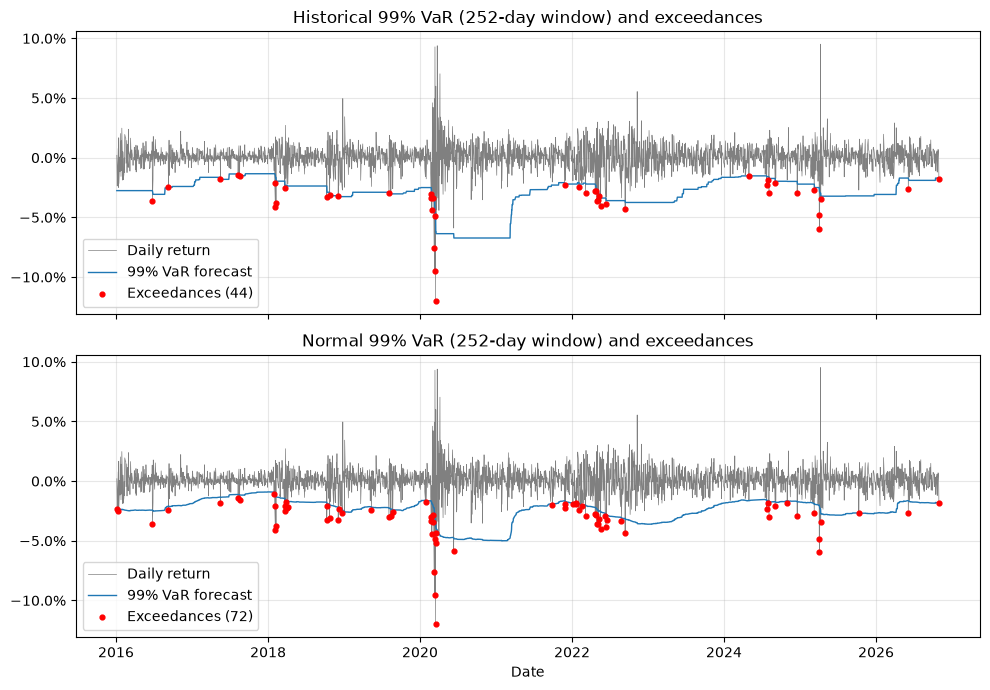

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

for ax, method in zip(axes, ("historical", "normal")):
    var99 = forecasts[(method, 0.99)]
    ret = r.loc[var99.index]
    exceed = ret < -var99

    ax.plot(ret.index, ret, color="grey", linewidth=0.5, label="Daily return")
    ax.plot(var99.index, -var99, color="tab:blue", linewidth=1, label="99% VaR forecast")
    ax.scatter(ret.index[exceed], ret[exceed], color="red", s=12, zorder=3,
               label=f"Exceedances ({exceed.sum()})")
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
    ax.set_title(f"{method.capitalize()} 99% VaR (252-day window) and exceedances")
    ax.legend(loc="lower left")
    ax.grid(alpha=0.3)

axes[1].set_xlabel("Date")
fig.tight_layout()
fig.savefig(FIGURES / "05_var_exceedances.png", dpi=150, bbox_inches="tight")
plt.show()

### Reading the backtest

| Model | Exceedances | Observed rate | Expected | Kupiec p-value | Result |
|---|---|---|---|---|---|
| Historical 95% | 139 | 5.11% | 5% | 0.80 | Not rejected |
| Historical 99% | 44 | 1.62% | 1% (~27 days) | 0.003 | Rejected |
| Normal 95% | 145 | 5.33% | 5% | 0.44 | Not rejected |
| Normal 99% | 72 | 2.65% | 1% (~27 days) | < 0.0001 | Rejected |

At 95%, both models pass. At 99%, both fail: the normal model is exceeded 2.6 times more often than
expected, because of fat tails. The historical model does better but is still rejected, because of
volatility clustering (Block 3): a one-year window adapts too slowly, so after a calm period the VaR is too
low when a crisis begins, and exceedances cluster (March 2020, 2022), as the chart shows.

The Kupiec test only checks the *number* of exceedances, not whether they cluster. The independence test
of Christoffersen (1998) addresses this. A natural improvement is to scale the VaR with a volatility model
that reacts faster (EWMA or GARCH), known as filtered historical simulation.

In [10]:
# 10-day VaR: square-root-of-time scaling vs. empirical 10-day returns
r10 = prices.pct_change(10).dropna()   # overlapping 10-day returns
var1 = historical_var(r, 0.99)

print(f"1-day 99% VaR:                      {var1:.2%}")
print(f"10-day 99% VaR, sqrt(10) scaling:   {var1 * np.sqrt(10):.2%}")
print(f"10-day 99% VaR, empirical:          {historical_var(r10, 0.99):.2%}")

1-day 99% VaR:                      3.21%
10-day 99% VaR, sqrt(10) scaling:   10.16%
10-day 99% VaR, empirical:          9.07%


### Square-root-of-time scaling

Regulators often require a 10-day VaR, commonly obtained by multiplying the 1-day VaR by sqrt(10).
Here, the scaled 10-day 99% VaR (10.16%) exceeds the VaR measured directly on overlapping 10-day returns
(9.07%). The square-root rule assumes independent and identically distributed returns: the short-term
negative autocorrelation found in Block 3, and the fact that tails become thinner when returns are
aggregated over several days, both reduce the true 10-day risk. The result is not general, however: in
crisis periods, volatility clustering can make sqrt(h) scaling underestimate risk, and the 10-day estimate
is noisy (only about 300 non-overlapping 10-day periods in the sample).

The backtest chart also shows a known weakness of historical VaR: it moves in steps, and drops abruptly
about 252 trading days after March 2020, when the extreme days leave the estimation window
(the "ghost effect"), even though nothing happened in the market on that day.

## Block 5: key takeaways

- The 1-day 99% VaR of the S&P 500 is **3.21%** (historical), and the 99% Expected Shortfall **4.59%**.
- **The normal model understates tail risk:** by about 21% for VaR and 37% for Expected Shortfall at 99%,
  while slightly overstating VaR at 95%, the signature of a leptokurtic distribution (Block 3).
- **Backtesting separates the models:** at 95% both pass the Kupiec (1995) test; at 99% both fail, the normal
  model severely (72 exceedances instead of about 27), the historical model more mildly (44).
- **Exceedances cluster in crises**, because a one-year window reacts too slowly to volatility changes.
  Scaling VaR with a faster volatility model (EWMA or GARCH) is the natural next step.
- Expected Shortfall, a coherent risk measure (Artzner et al., 1999), captures the size of tail losses
  that VaR ignores, which is why it has become the regulatory reference for market risk.